In [8]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica']
mpl.rcParams['figure.dpi'] = 200

def cm2inch(*tupl):
    inch = 2.54
    if isinstance(tupl[0], tuple):
        return tuple(i/inch for i in tupl[0])
    else:
        return tuple(i/inch for i in tupl)

params = {
   'axes.labelsize': 7,
   'axes.spines.top'  : False ,
   'axes.spines.right'  : False ,
   'axes.linewidth' : 0.5,
   'axes.unicode_minus' : False,
   'font.size': 7,
   'legend.fontsize': 7,
   'xtick.major.top'      : False,
   'ytick.major.right'      : False,
    'xtick.labelsize'      : 7 ,
    'ytick.labelsize'     : 7 ,
   'figure.figsize': [2,2],
   'lines.linewidth' : 0.5,
   #'errorbar.capsize' : 10,
'mathtext.fontset' : 'cm',
"figure.subplot.left"    : 0.35 , # the left side of the subplots of the figure
"figure.subplot.right"   : 0.9   , # the right side of the subplots of the figure
"figure.subplot.bottom"   : 0.25  ,  # the bottom of the subplots of the figure
"figure.subplot.top"     : 0.97 ,
    "figure.dpi" : 200 ,
   'xtick.major.pad' : 1,
   'ytick.major.pad' : 1,
    'xtick.major.width':   0.5,
   'xtick.major.size':   1.5,
    'ytick.major.width':   0.5,
   'ytick.major.size':   1.5,
    'pdf.fonttype': 42,
    'pdf.use14corefonts'  : True
}
#Matplotlib.rcParams[‘pdf.- fonttype’]=42
mpl.rcParams.update(params)

import matplotlib.animation as animation
%matplotlib inline

In [5]:
iris_data=np.loadtxt("fisher_iris_shuffled.txt")
print("Shape",iris_data.shape, "(Samples, Variables)")

Shape (150, 3)


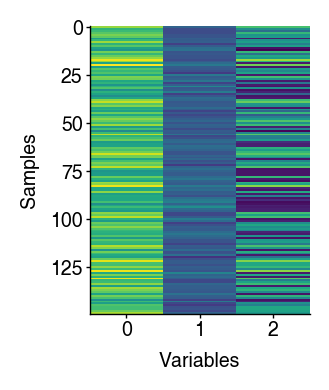

In [17]:


plt.imshow(iris_data, aspect='auto', interpolation='None')
plt.xlabel("Variables")
plt.ylabel("Samples")
plt.show()



<IPython.core.display.Javascript object>


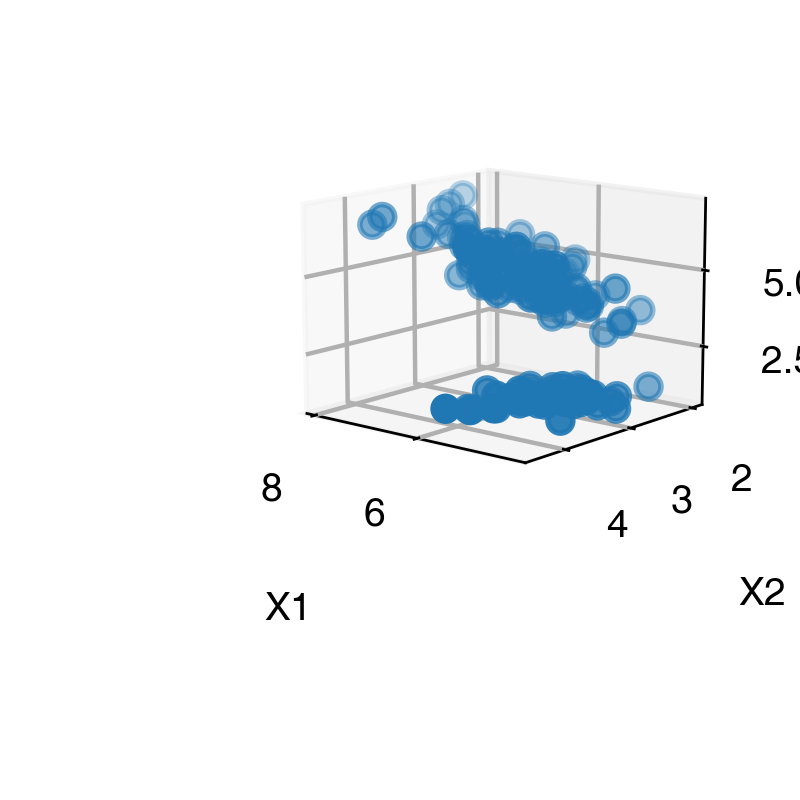

In [253]:
%matplotlib notebook
fig=plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(iris_data[:,0], iris_data[:,1], iris_data[:,2] )
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
plt.show()

## PCA from scratch



In [35]:
%matplotlib inline

In [255]:
#preprocessing (whitening)
iris_data_zscored = iris_data - iris_data.mean(0)[None,:]
iris_data_zscored = iris_data_zscored/iris_data.std(0)[None,:]

#calc covariance
covariance_iris = (1./(iris_data.shape[0]))*iris_data_zscored.T@iris_data_zscored

#calc eigenvectors and values of covariance
eigvals, eigvecs = np.linalg.eigh(covariance_iris)
eigvecs = eigvecs[:,np.argsort(eigvals)[::-1]]
eigvals = np.sort(eigvals)[::-1]


In [256]:
print(eigvals, eigvecs)
#Eigenvalues tell you how much variance lies in the direction of this eigenvector

[2.01382631 0.91483072 0.07134297] [[-0.63137983  0.42771052  0.64685642]
 [ 0.35424227  0.90110216 -0.25005463]
 [-0.6898347   0.07126444 -0.72045087]]


variance along dimension PC1 2.0138263072086584


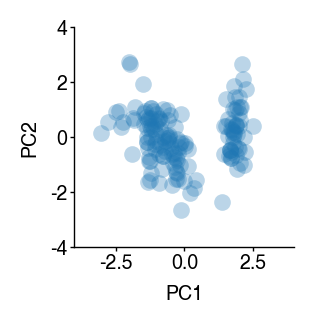

variance along dimension PC1 2.0138263072086584


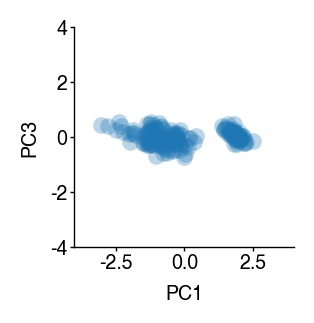

variance along dimension PC2 0.9148307201559231


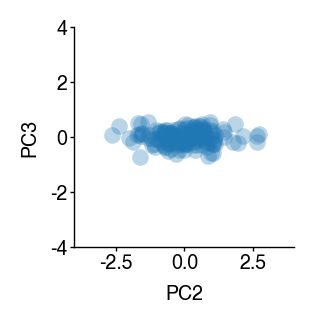

In [61]:
for i in range(3):
    for j in range(i+1,3):
        #print("PC{}".format(i+1),"PC{}".format(j+1) )
        
        xdata = iris_data_zscored@eigvecs[:,i]
        ydata = iris_data_zscored@eigvecs[:,j]
        print("variance along dimension PC{}".format(i+1), np.var(xdata))
        
        fig=plt.figure()
        plt.scatter(xdata, ydata, alpha=0.3, lw=0)
        plt.xlabel("PC{}".format(i+1))
        plt.ylabel("PC{}".format(j+1))
        plt.axis("square")
        plt.axis([-4,4,-4,4])
        plt.show()

In [257]:
## compare normalized variances and eigenvalues
for j in range(3):
    ydata = iris_data_zscored@eigvecs[:,j]
    print("variance along dimension PC{}".format(j+1), np.var(ydata))
    print("relative variance", np.var(ydata)/np.trace(covariance_iris))
    print("relative eigenvalue", eigvals[j]/np.sum(eigvals))
    print("\n")

variance along dimension PC1 2.013826307208657
relative variance 0.6712754357362186
relative eigenvalue 0.6712754357362188


variance along dimension PC2 0.9148307201559235
relative variance 0.30494357338530764
relative eigenvalue 0.3049435733853077


variance along dimension PC3 0.07134297263542028
relative variance 0.02378099087847341
relative eigenvalue 0.023780990878473553




In [63]:
print("total variance", np.trace(covariance_iris))

total variance 3.0201342281879198


<IPython.core.display.Javascript object>


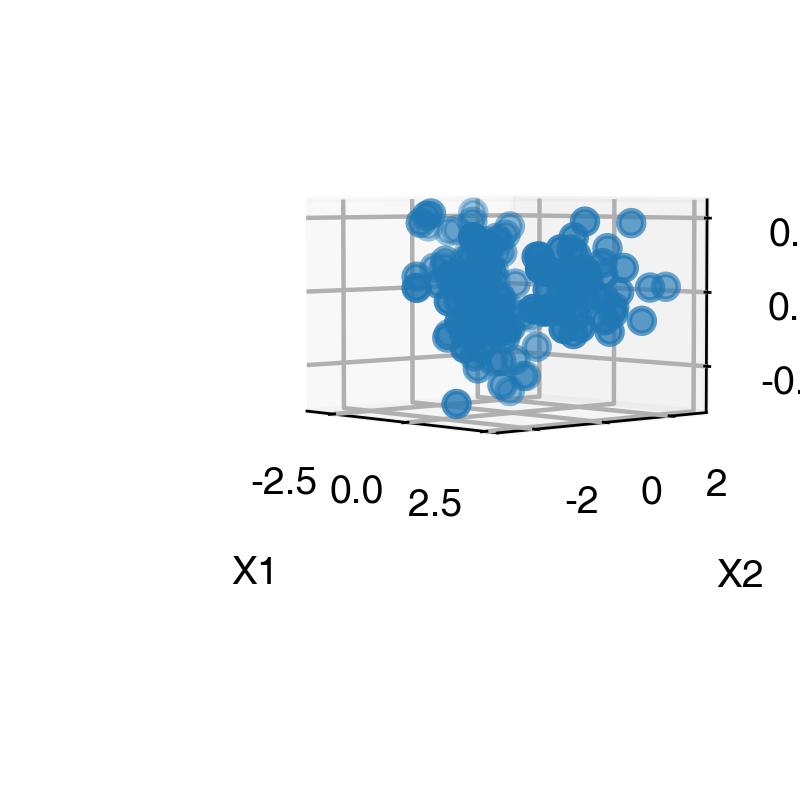

In [258]:
%matplotlib notebook
fig=plt.figure()
ax = fig.add_subplot(projection='3d')

tgransformed_data = ydata = iris_data_zscored@eigvecs
ax.scatter(tgransformed_data[:,0], tgransformed_data[:,1], tgransformed_data[:,2] )
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
plt.show()

## Compare tsne and pca

In [74]:
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


In [146]:
# Get images
mnist = fetch_openml(name='mnist_784', as_frame=False, parser='auto')
X_all = mnist.data
# Get labels
labels_all = np.array([int(k) for k in mnist.target])

Ndatapoint=7000
X_all_short = X_all[:Ndatapoint]

<IPython.core.display.Javascript object>


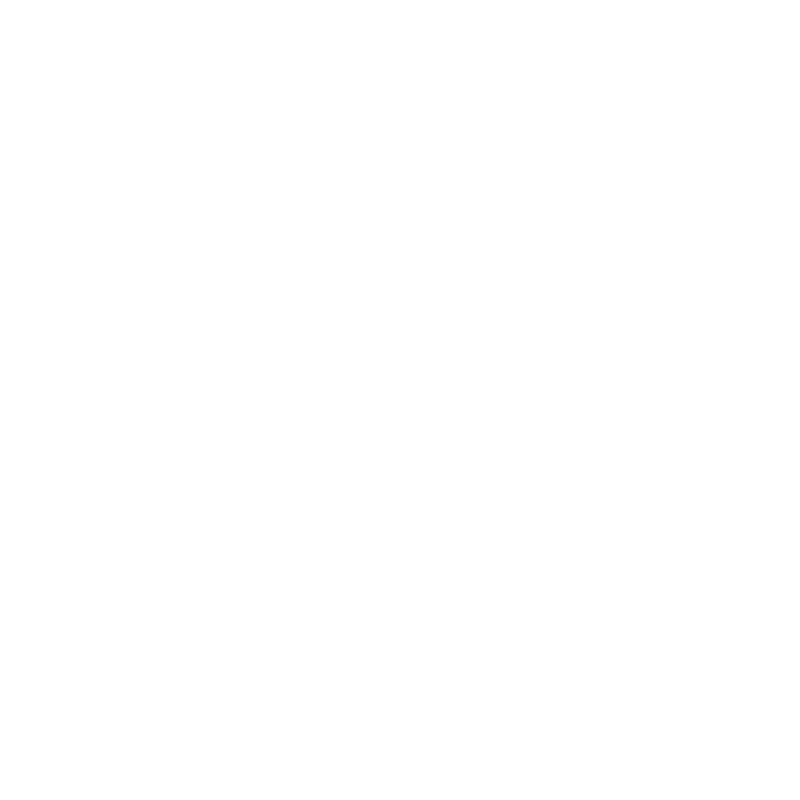

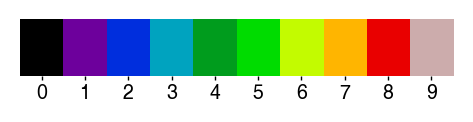

In [251]:

colormap_name='nipy_spectral'
color_list=mpl.colormaps[colormap_name](np.linspace(0, 0.99, 10))

%matplotlib inline
color_list_image = np.array(color_list).reshape(-1, 4)
color_list_image=np.array(color_list_image).reshape(1,10, 4)

fig=plt.figure(figsize=cm2inch(10,1))
plt.imshow(color_list_image, aspect='auto')
plt.xticks(np.arange(10), np.arange(10))
plt.yticks([])
ax=plt.gca()
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.show()

### PCA

In [147]:
pca_mnist = PCA(n_components=3)
pca_mnist = pca_mnist.fit(X_all_short)
mnist_trafo_pca = pca_mnist.transform(X_all_short)

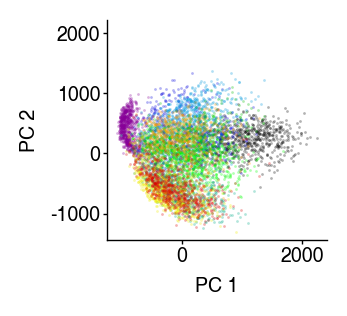

In [191]:
%matplotlib inline
fig=plt.figure()
ax=fig.add_subplot()


ax.set_prop_cycle(color=color_list)
for digit in range(10):
    indices = (labels_all[:Ndatapoint]==digit)
    xdata=mnist_trafo_pca[indices,0]
    ydata=mnist_trafo_pca[indices,1]
    plt.scatter(xdata, 
                ydata,
               alpha=0.3, lw=0,s=1)

    
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')    
ax.axis("square")
plt.show()

<IPython.core.display.Javascript object>


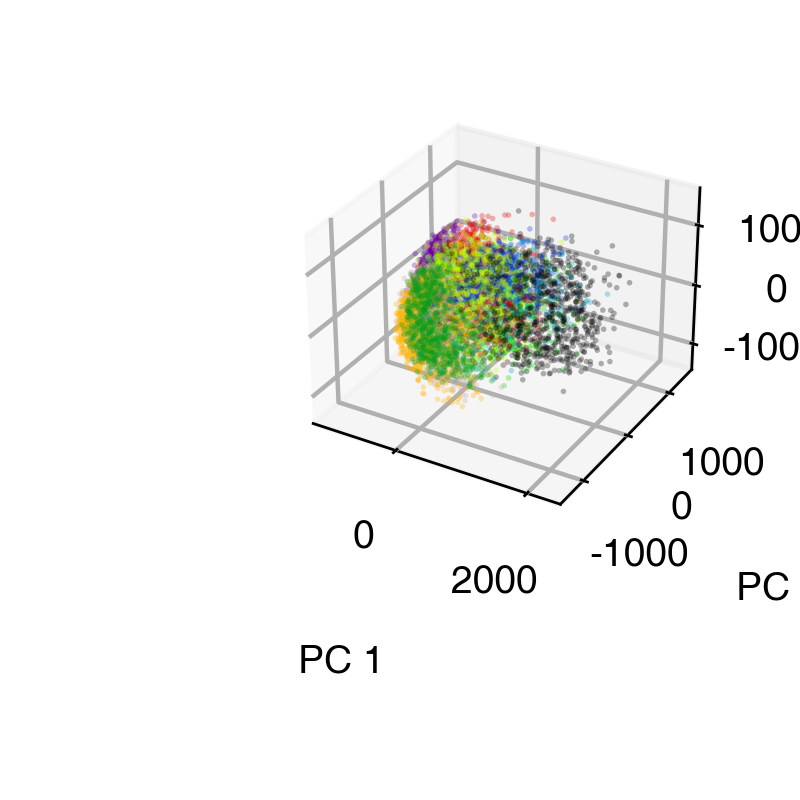

In [203]:
%matplotlib notebook
fig=plt.figure()
ax = fig.add_subplot(projection='3d')


ax.set_prop_cycle(color=color_list)
for digit in range(10):
    indices = (labels_all[:Ndatapoint]==digit)
    xdata=mnist_trafo_pca[indices,0]
    ydata=mnist_trafo_pca[indices,1]
    zdata=mnist_trafo_pca[indices,2]
    ax.scatter(xdata, 
                ydata,
                zdata,
               alpha=0.3, lw=0,s=1)
ax=plt.gca()
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')    
#ax.axis("square")
plt.show()

### tsne in 2d

In [261]:
Ndatapoint=3000

mnist_trafo_tsne = TSNE(n_components=2, learning_rate='auto',
                 init='random', perplexity=50).fit_transform(X_all_short[:Ndatapoint])
mnist_trafo_tsne.shape                                                           

(3000, 2)

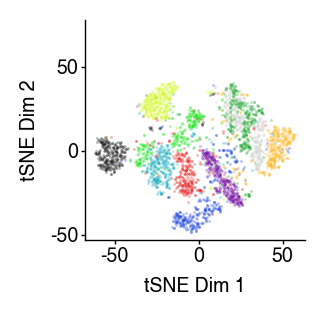

In [262]:
%matplotlib inline
fig=plt.figure()
ax=fig.add_subplot()

ax.set_prop_cycle(color=color_list)

for digit in range(10):
    indices = (labels_all[:Ndatapoint]==digit)
    xdata=mnist_trafo_tsne[indices,0]
    ydata=mnist_trafo_tsne[indices,1]
    plt.scatter(xdata, 
                ydata,
               alpha=0.3, lw=0,s=1)

    
ax.set_xlabel('tSNE Dim 1')
ax.set_ylabel('tSNE Dim 2')   
ax.axis("square")
plt.show()

In [249]:
mnist_trafo_tsne3d = TSNE(n_components=3, learning_rate='auto',
                 init='random', perplexity=20).fit_transform(X_all_short) 

<IPython.core.display.Javascript object>


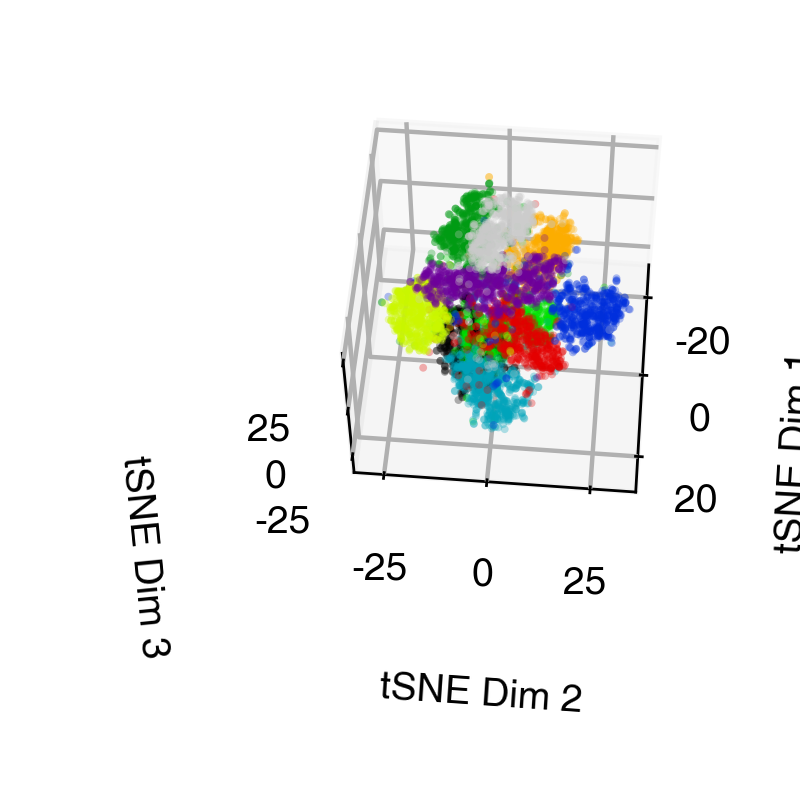

In [264]:
Ndatapoint=7000
%matplotlib notebook
fig=plt.figure()
ax = fig.add_subplot(projection='3d')

color_list=mpl.colormaps[colormap_name](np.linspace(0, 1, 10))
ax.set_prop_cycle(color=color_list)

for digit in range(10):
    indices = (labels_all[:Ndatapoint]==digit)
    xdata=mnist_trafo_tsne3d[indices,0]
    ydata=mnist_trafo_tsne3d[indices,1]
    zdata=mnist_trafo_tsne3d[indices,2]
    ax.scatter(xdata, 
                ydata,
                zdata,
               alpha=0.3, lw=0,s=2)
ax=plt.gca()
ax.set_xlabel('tSNE Dim 1')
ax.set_ylabel('tSNE Dim 2')    
ax.set_zlabel('tSNE Dim 3') 
plt.show()                                                        